# Title
Adam Noonan | C00299231

## Introduction

stuff stuff stuff

In [9]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

filename = r"../exoplanets_slim_2026-11-3.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
print(df.dtypes)

(6451, 23)
pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_period            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object


## Preprocessing
- thingy
- thingy

In [15]:
d = df[[
    "pl_orb_eccen",
    "pl_temp",
    "pl_mass_e",
    "pl_orb_period",
    "pl_radius_e"
]].dropna()

print(len(df), "->", len(d))

6451 -> 5254


In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix


def do_classification(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=29, stratify=y
    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Round Orbit", "Eccentric Orbit"]
    )

    print(y_test.value_counts())
    print(y_pred)

    display.plot(cmap="Blues")
    plt.show()

Accuracy: 0.7511415525114156
              precision    recall  f1-score   support

           0       0.75      0.89      0.81       801
           1       0.76      0.53      0.63       513

    accuracy                           0.75      1314
   macro avg       0.75      0.71      0.72      1314
weighted avg       0.75      0.75      0.74      1314

pl_orb_eccen
0    801
1    513
Name: count, dtype: int64
[0 0 0 ... 1 0 0]


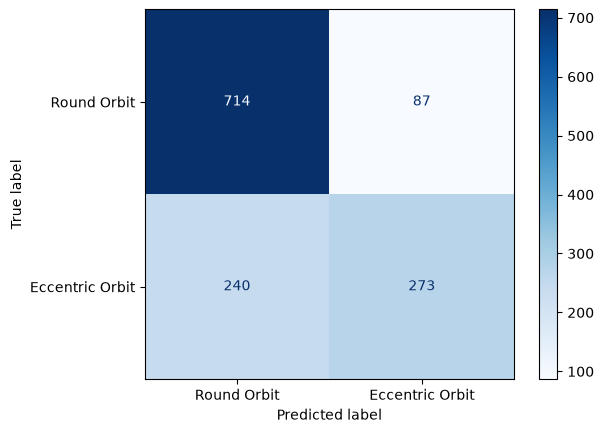

In [12]:
X = d[[
    "pl_temp",
    "pl_orb_period",
    "pl_radius_e"
]]

y = (d["pl_orb_eccen"] > 0.01).astype(int)
do_classification(X, y)

Accuracy: 0.7800608828006088
              precision    recall  f1-score   support

           0       0.79      0.90      0.84       849
           1       0.75      0.56      0.64       465

    accuracy                           0.78      1314
   macro avg       0.77      0.73      0.74      1314
weighted avg       0.78      0.78      0.77      1314

pl_orb_eccen
0    849
1    465
Name: count, dtype: int64
[0 0 0 ... 0 1 0]


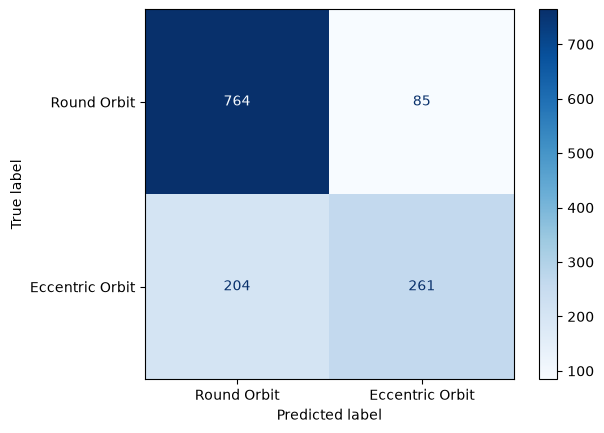

In [13]:

y = (d["pl_orb_eccen"] > 0.03).astype(int)
do_classification(X, y)

Accuracy: 0.8424657534246576
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      1014
           1       0.76      0.45      0.57       300

    accuracy                           0.84      1314
   macro avg       0.81      0.70      0.73      1314
weighted avg       0.83      0.84      0.83      1314

pl_orb_eccen
0    1014
1     300
Name: count, dtype: int64
[0 0 0 ... 0 1 0]


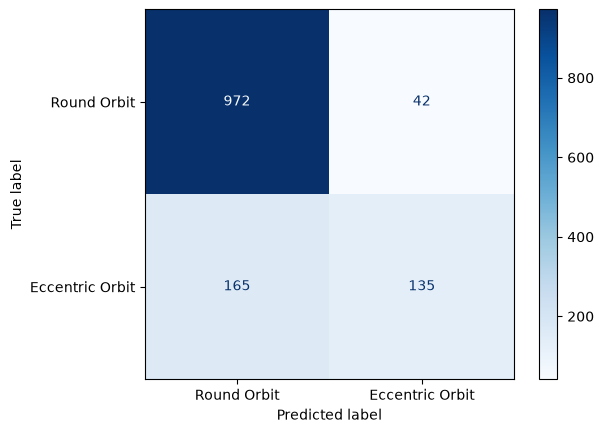

In [14]:
y = (d["pl_orb_eccen"] > 0.1).astype(int)
do_classification(X, y)

## Results and Conclusion